# [8.8] Benchmarking Circuit Discovery on Compiled Transformers (exercises)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter8_automated_circuits/exercises/part8_circuit_benchmarks/8.8_Benchmarking_Circuit_Discovery_on_Compiled_Transformers_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter8_automated_circuits/exercises/part8_circuit_benchmarks/8.8_Benchmarking_Circuit_Discovery_on_Compiled_Transformers_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-13-2.png" width="350">

# Introduction

Given `BOS 15 5 4 3 13 1 14 6 15`, an induction model should predict `5`: it finds the earlier `15` and copies the token after it. Suppose two methods explain that same correct
prediction with different edges. How can we tell which method recovered the computation? This time we will write the computation into the weights, so we have an answer key.

Over this chapter you've built five ways of finding circuits: exact activation patching ([8.1]), attribution patching and EAP ([8.2]), EAP-IG ([8.2]), AtP* ([8.3]) and ACDC
([8.4]), plus causal scrubbing for testing the result ([8.5]). Every time, we evaluated them against each other, against random baselines, or against circuits that people found by
hand. What we never had was an **answer key**: a model whose true circuit we know for certain, so that "did the method find it?" has a definite answer.

There's one way to get an answer key: build the model yourself. **RASP** (Weiss, Goldberg & Yahav, 2021) is a programming language whose primitives map directly onto transformer
components, and **Tracr** (Lindner et al., 2023) compiles RASP programs into the weights of a real transformer. The compiled weights implement the program; our finite-softmax
version approximates its hard selection and solves the measured task perfectly. In this section you'll write a tiny compiler of your own, compile an induction program (with a
redundant backup head and some distractors), and use it to benchmark the methods from this chapter.

Here's a preview of what you'll find. On the clean compiled model, every method looks perfect. Add a little noise to the weights, as any trained model has, and EAP collapses to a
ROC AUC of about 0.6, while EAP-IG and exact patching keep AUC 1, and ACDC recovers the seven planted edges without extras at low noise. The reason is the same one that [8.3]
studied for single components, in its purest form: a compiled model is *maximally confident*, so every gradient you'd want to use is close to zero. You'll take that apart at the
level of single nodes, and see exactly which fixes help with which kind of saturation. Then, in the last part, you'll go back to GPT-2, where there's no answer key, measure how
much the methods agree and how faithful their circuits are, and end the chapter with a guide to choosing a method.

This section assumes [8.2], [8.3] and [8.4], whose implementations it imports.

## Content & Learning Objectives

### 1️⃣ Compiling a Program into Weights

You'll learn how RASP's primitives map onto attention heads, write a compiler for the `select`/`aggregate` primitive, and compile an induction program into a two-layer transformer
that solves the task perfectly. Its circuit is known exactly.

> ##### Learning Objectives
>
> - Understand the RASP view of a transformer: categorical variables in orthogonal subspaces of the residual stream, and attention as select-and-aggregate
> - Implement a compiler for select/aggregate, by writing $W_Q$, $W_K$, $W_V$ and $W_O$ directly
> - Compile an induction program, including a redundant backup head and distractor heads, and verify it
> - Derive the ground-truth circuit from the program, relative to a corruption

### 2️⃣ Benchmarking Edge Attribution

You'll score every edge of the compiled model with exact single-edge patching, EAP and integrated gradients, run ACDC, and measure each against the ground truth with ROC AUC, both
on the clean model and as noise is added to its weights.

> ##### Learning Objectives
>
> - Write EAP and EAP-IG as derivatives of the metric with respect to the edge mask
> - Implement ROC AUC against a ground-truth circuit, and use a random ranking as the baseline
> - Understand why a clean compiled model is a misleadingly easy benchmark, and use weight noise to make it harder
> - Compare methods by accuracy *and* cost

### 3️⃣ Why Gradients Fail, and What Fixes Them

You'll use the AtP and AtP* implementations from [8.3] on the compiled model to find where the gradients vanish, and show which direct effects the metric change and QK fix recover,
and which upstream effects they still miss.

> ##### Learning Objectives
>
> - Distinguish saturation of the output (the metric) from saturation of attention
> - See the QK fix recover a saturated head's queries and keys exactly, and fail for nodes whose effect passes *through* a saturated head
> - Understand why integrated gradients handle both

### 4️⃣ No Answer Key: GPT-2, and Choosing a Method

You'll run EAP, EAP-IG and ACDC on GPT-2's greater-than task, measure their agreement and the faithfulness of their circuits, and summarise the chapter in a method-choice guide.

> ##### Learning Objectives
>
> - Measure agreement between methods when there's no ground truth, and understand why agreement isn't correctness
> - Compare circuits from different methods at matched size on held-out prompts
> - Choose a circuit-discovery method for a given model, budget and question

### ☆ Bonus

Real Tracr, more programs, compiled MLPs, InterpBench, and further reading.

## Setup code

In [ ]:
import os
import sys
#
IN_COLAB = "google.colab" in sys.modules
#
if IN_COLAB:
    # Install dependencies, and download this chapter's exercise files from the ARENA extension repo
    %pip install transformer_lens==2.16.1 jaxtyping
    repo, branch, chapter = "ARENA_3.0_Extended", "main", "chapter8_automated_circuits"
    if not os.path.exists(f"/content/{chapter}"):
        !wget -P /content https://github.com/shinobiultra/{repo}/archive/refs/heads/{branch}.zip
        !unzip -q /content/{branch}.zip '{repo}-{branch}/{chapter}/exercises/*' -d /content
        !mv /content/{repo}-{branch}/{chapter} /content/{chapter}
        !rm -r /content/{branch}.zip /content/{repo}-{branch}
    os.chdir(f"/content/{chapter}/exercises")

In [ ]:
import sys
import time
from collections.abc import Callable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch as t
from IPython.display import display
from jaxtyping import Float
from torch import Tensor
from transformer_lens import HookedTransformer

device = t.device("mps" if t.backends.mps.is_available() else "cuda" if t.cuda.is_available() else "cpu")

# Make sure exercises are in the path
chapter = "chapter8_automated_circuits"
section = "part8_circuit_benchmarks"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

import part8_circuit_benchmarks.tests as tests
import part8_circuit_benchmarks.utils as utils

# Methods from earlier sections: EAP / EAP-IG and the GPT-2 graph ([8.2]), AtP and AtP* ([8.3]), ACDC ([8.4])
import part2_attribution_patching_eap.solutions as eap_8_2
import part3_atp_star.solutions as atp_8_3
import part4_acdc_circuit_metrics.solutions as acdc_8_4
import part4_acdc_circuit_metrics.utils as acdc_utils

MAIN = __name__ == "__main__"

# 1️⃣ Compiling a Program into Weights

> ##### Learning Objectives
>
> - Understand the RASP view of a transformer: categorical variables in orthogonal subspaces of the residual stream, and attention as select-and-aggregate
> - Implement a compiler for select/aggregate, by writing $W_Q$, $W_K$, $W_V$ and $W_O$ directly
> - Compile an induction program, including a redundant backup head and distractor heads, and verify it
> - Derive the ground-truth circuit from the program, relative to a corruption

## Transformers as programs

RASP describes what a transformer can compute with a handful of primitives that act on whole sequences at once. The two we need:

- **`select(keys, queries, predicate)`** builds a boolean matrix $S_{ij} = \text{predicate}(\text{query}_i, \text{key}_j)$, saying which positions $j$ each position $i$ looks at. That's an attention pattern.
- **`aggregate(S, values)`** averages the selected positions' values. That's what the attention head's OV circuit does with the pattern.

(RASP also has `map`, an elementwise function, which compiles to an MLP. We won't need it for induction.)

In those terms, induction is a two-line program:

```python
prev_token = aggregate(select(indices, indices, lambda k, q: k == q - 1), tokens)   # layer 0
prediction = aggregate(select(prev_token, tokens, lambda k, q: k == q), tokens)      # layer 1
```

The first line looks one position back and copies the token there. The second looks for the position whose *previous* token equals the current token, and copies the token at that
position: the next token after the last occurrence of the current one.

To compile this, Tracr gives every variable (`tokens`, `indices`, `prev_token`, `prediction`) its own block of dimensions in the residual stream, and stores a categorical variable
with $n$ possible values as a one-hot vector in an $n$-dimensional block. Every head then reads from some blocks and writes to others, and nothing ever interferes, because the
blocks are orthogonal. We'll do the same.

## The residual stream layout

Our vocabulary has 16 tokens (token 0 is BOS), and prompts have length 17: BOS followed by 8 distinct tokens, repeated. The residual stream has one block per variable, plus a
"junk" block that distractor heads use but no output-relevant head reads:

In [ ]:
VOCAB, HALF_LEN = 16, 8
SEQ = 2 * HALF_LEN + 1
N_LAYERS, N_HEADS, D_HEAD = 2, 3, 17

SUBSPACES: dict[str, slice] = {}
_start = 0
for _name, _size in [("tok", VOCAB), ("pos", SEQ), ("prev", VOCAB), ("out", VOCAB), ("junk", VOCAB)]:
    SUBSPACES[_name] = slice(_start, _start + _size)
    _start += _size
D_MODEL = _start

print(f"d_model = {D_MODEL}:", {name: (s.start, s.stop) for name, s in SUBSPACES.items()})


def make_empty_model() -> HookedTransformer:
    return utils.empty_attn_only_model(N_LAYERS, N_HEADS, D_MODEL, D_HEAD, VOCAB, SEQ, device)

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">d_model = 81: {'tok': (0, 16), 'pos': (16, 33), 'prev': (33, 49), 'out': (49, 65), 'junk': (65, 81)}</pre>

</details>

### Exercise - compile `select` and `aggregate` into a head

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20-25 minutes on this exercise.
> ```

Implement `compile_select_aggregate`, which writes one attention head so that:

- **The attention scores implement the predicate.** For a residual stream whose `query_space` block is the one-hot vector $e_a$ and whose `key_space` block is $e_b$, the score (after TransformerLens divides by $\sqrt{d_{head}}$) is `sharpness * predicate[a, b]`. A large `sharpness` makes the softmax pick out the selected positions almost exactly.
- **The OV circuit copies `value_space` into `out_space`**, multiplied by `amplitude`.

`predicate` is a 0/1 matrix of shape `(query values, key values)`. The cleanest construction uses the head's $d_{head}$ dimensions to index *key values*: let $W_K$ map each key
value $b$ to the basis vector $e_b$, and $W_Q$ map each query value $a$ to the row `predicate[a]` (scaled so the scores come out right). For the OV circuit, let $W_V$ map value $c$
to $e_c$ and $W_O$ map $e_c$ back to the $c$-th dimension of `out_space`.

Write only the weights of the given head (`model.blocks[layer].attn.W_Q[head]` and so on, inside `t.no_grad()`); the model starts with all weights at zero, and the biases stay
zero.

In [ ]:
def compile_select_aggregate(
    model: HookedTransformer,
    layer: int,
    head: int,
    query_space: slice,
    key_space: slice,
    predicate: Float[Tensor, "query_values key_values"],
    value_space: slice,
    out_space: slice,
    sharpness: float = 20.0,
    amplitude: float = 1.0,
) -> None:
    """Writes head (layer, head) so that it attends according to `predicate` and copies value_space into out_space."""
    raise NotImplementedError()


tests.test_select_aggregate(compile_select_aggregate, lambda: make_empty_model().cpu(), SUBSPACES)

<details>
<summary>Hint</summary>

With $W_Q[\text{query\_space}, :n_{key}] = c \cdot \text{predicate}$ and $W_K[\text{key\_space}, :n_{key}] = I$, a one-hot query $e_a$ and key $e_b$ give $q \cdot k = c \cdot
\text{predicate}[a, b]$. TransformerLens divides by $\sqrt{d_{head}}$, so choose $c = \text{sharpness} \cdot \sqrt{d_{head}}$.
</details>


<details><summary>Solution</summary>

```python
def compile_select_aggregate(
    model: HookedTransformer,
    layer: int,
    head: int,
    query_space: slice,
    key_space: slice,
    predicate: Float[Tensor, "query_values key_values"],
    value_space: slice,
    out_space: slice,
    sharpness: float = 20.0,
    amplitude: float = 1.0,
) -> None:
    """Writes head (layer, head) so that it attends according to `predicate` and copies value_space into out_space."""
    attn = model.blocks[layer].attn
    n_query, n_key = predicate.shape
    n_value = value_space.stop - value_space.start
    with t.no_grad():
        attn.W_Q[head][query_space, :n_key] = predicate.to(attn.W_Q.device) * sharpness * model.cfg.d_head**0.5
        attn.W_K[head][key_space, :n_key] = t.eye(n_key, device=attn.W_K.device)
        attn.W_V[head][value_space, :n_value] = t.eye(n_value, device=attn.W_V.device)
        attn.W_O[head][:n_value, out_space] = t.eye(n_value, device=attn.W_O.device) * amplitude
```
</details>

## Compiling the induction program

Now we compile the program, plus three things that make it a more interesting test:

- **A backup head.** Layer 0 has *two* previous-token heads, 0.0 and 0.1, both writing to the `prev` block. Real models are full of this kind of redundancy (remember the backup name movers in [8.1]), and it's a classic source of trouble for circuit discovery.
- **Distractors.** Head 0.2 averages the tokens over all previous positions, and writes the result to `junk`. Head 1.1 reads `junk` and writes back to `junk`. Head 1.2 copies the current token to `junk`. None of them can affect the output in the clean compiled model: head 1.1 reads `junk`, but no path carries it to `out` or the unembedding.
- **Embedding and unembedding.** The embedding writes the token one-hot into `tok`, the positional embedding writes the position one-hot into `pos`, and the unembedding reads `out` (scaled by 10, so that a fully attended token gets a confident prediction).

The cell below builds it, using your compiler.

In [ ]:
def compile_induction() -> HookedTransformer:
    model = make_empty_model()
    tok, pos, prev, out, junk = (SUBSPACES[k] for k in ["tok", "pos", "prev", "out", "junk"])
    with t.no_grad():
        model.embed.W_E[:, tok] = t.eye(VOCAB, device=device)
        model.pos_embed.W_pos[:, pos] = t.eye(SEQ, device=device)
        model.unembed.W_U[out, :] = 10 * t.eye(VOCAB, device=device)

    previous_position = t.zeros(SEQ, SEQ)
    for i in range(1, SEQ):
        previous_position[i, i - 1] = 1
    same_token = t.eye(VOCAB)
    # Layer 0: two redundant previous-token heads, and a distractor that averages all tokens into junk
    for head in [0, 1]:
        compile_select_aggregate(model, 0, head, pos, pos, previous_position, tok, prev)
    compile_select_aggregate(model, 0, 2, pos, pos, t.zeros(SEQ, SEQ), tok, junk)
    # Layer 1: the induction head, and two distractors writing to junk
    compile_select_aggregate(model, 1, 0, tok, prev, same_token, tok, out)
    compile_select_aggregate(model, 1, 1, junk, junk, same_token, junk, junk)
    compile_select_aggregate(model, 1, 2, pos, pos, t.eye(SEQ), tok, junk)
    return model


compiled = compile_induction()
data_generator = t.Generator().manual_seed(0)
clean, corrupt = utils.make_induction_data(64, VOCAB, HALF_LEN, data_generator, device)
POS = slice(HALF_LEN + 1, 2 * HALF_LEN)  # positions where the next token is predictable


def induction_logprob(logits: Tensor) -> Tensor:
    """Mean log probability of the correct next token at the induction positions (uses the global `clean`)."""
    logprobs = logits[:, POS].log_softmax(dim=-1)
    return logprobs.gather(-1, clean[:, POS.start + 1 : POS.stop + 1, None]).mean()


with t.no_grad():
    for name, toks in [("clean", clean), ("corrupted", corrupt)]:
        logits = compiled(toks)
        accuracy = (logits[:, POS].argmax(-1) == clean[:, POS.start + 1 : POS.stop + 1]).float().mean()
        print(f"{name:<10} prompts: log prob of the induction answer {induction_logprob(logits):.4f}, accuracy {accuracy:.1%}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">clean      prompts: log prob of the induction answer -0.0007, accuracy 100.0%
corrupted  prompts: log prob of the induction answer -5.4920, accuracy 8.0%</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

The targets are always the next tokens in the **clean** repeated sequence, even when the model receives corrupted tokens. On 64 clean prompts, all 7 scored positions per prompt are
correct: 448 predictions in total. The mean log probability is close to zero, so the model is also very confident. The 8.0% corrupted accuracy is a useful control: an unrelated
sequence does not supply the original induction answers. It is close to the 1/15 chance scale for the non-BOS tokens, rather than a second successful induction task.

This establishes the behavior before we try to explain it. It does not yet tell us which heads cause that behavior; the attention patterns and interventions below address that
question.
</details>


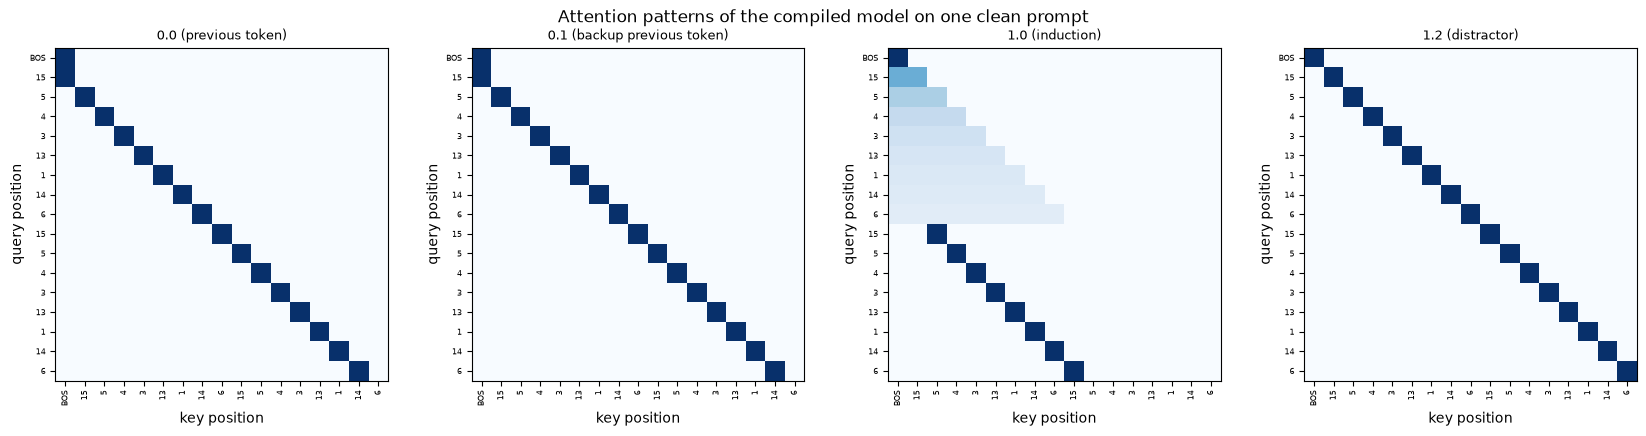

In [ ]:
with t.no_grad():
    _, cache = compiled.run_with_cache(clean[:1])
str_tokens = ["BOS"] + [str(tok) for tok in clean[0, 1:].tolist()]
utils.plot_patterns(
    {
        "0.0 (previous token)": cache["blocks.0.attn.hook_pattern"][0, 0],
        "0.1 (backup previous token)": cache["blocks.0.attn.hook_pattern"][0, 1],
        "1.0 (induction)": cache["blocks.1.attn.hook_pattern"][0, 0],
        "1.2 (distractor)": cache["blocks.1.attn.hook_pattern"][0, 2],
    },
    str_tokens,
    "Attention patterns of the compiled model on one clean prompt",
)

Read each row as a query choosing earlier key positions. Heads 0.0 and 0.1 have matching previous-token stripes. Head 1.0 has the induction stripe in the second half: at the second
`15`, it attends to the earlier `5`, whose stored previous token is `15`. In the first half there is no matching earlier token, so its rows are diffuse rather than one-hot. Head
1.2 attends to the current position but writes only to `junk`: a sharp attention pattern alone is not evidence of a task-relevant head. The selected-position patterns are nearly
hard because `sharpness` is large; their small local derivatives will matter in 3️⃣.

## The ground-truth circuit

Which edges of the [8.4]-style graph (senders: the input and the 6 heads; receivers: each head's q, k and v, and the logits) are in the circuit? Reading it off the program:

- `input -> 0.0<v>` and `input -> 0.1<v>`: the previous-token heads copy the token;
- `0.0 -> 1.0<k>` and `0.1 -> 1.0<k>`: the induction head's keys read `prev`;
- `input -> 1.0<q>` and `input -> 1.0<v>`: its query and value read the token;
- `1.0 -> logits`: the prediction is read out.

What about `input -> 0.0<q>` and `input -> 0.0<k>`? The previous-token heads' attention is computed from the positional embedding, which is part of the `input` sender, so these
edges *are* used. But positions are identical in the clean and corrupted prompts, so cutting these edges changes nothing, and no method that compares clean and corrupted runs can
ever see them. A ground truth only makes sense **relative to the contrast you measure**, so we leave them out. (This is the same point as [8.4]'s finding that the circuit depends
on the corruption.)

That's 7 edges out of 52. The other 45 have no effect under this clean-model corruption intervention. This is an answer key for this graph and contrast, rather than every
dependency needed to execute the program under arbitrary changes.

In [ ]:
GROUND_TRUTH_EDGES = [
    ("input", "0.0<v>"), ("input", "0.1<v>"), ("0.0", "1.0<k>"), ("0.1", "1.0<k>"),
    ("input", "1.0<q>"), ("input", "1.0<v>"), ("1.0", "logits"),
]

## Making the benchmark harder: weight noise

A compiled model is unrealistically clean: every edge outside the circuit has *exactly* zero effect. Any method that gives the circuit's edges a nonzero score, however tiny or
meaningless, will rank them perfectly. A trained model need not have these isolated subspaces or exact zeros. Adding noise is a controlled way to break that convenience, rather
than a claim that trained weights are literally compiled weights plus Gaussian noise.

So we'll add a knob: Gaussian noise with standard deviation $\sigma$ added to every attention weight ($W_Q$, $W_K$, $W_V$, $W_O$). For small $\sigma$ the model still computes the
program (we'll check), but the edges outside the circuit get small, nonzero effects, and a method now has to separate signal from noise.

In [ ]:
def add_weight_noise(model: HookedTransformer, sigma: float, seed: int = 0) -> HookedTransformer:
    generator = t.Generator().manual_seed(seed)
    with t.no_grad():
        for name, param in model.named_parameters():
            if name.split(".")[-1] in ("W_Q", "W_K", "W_V", "W_O"):
                param.add_(t.randn(param.shape, generator=generator).to(param.device) * sigma)
    return model


with t.no_grad():
    for sigma in [0.0, 0.01, 0.03, 0.1]:
        noisy = add_weight_noise(compile_induction(), sigma)
        logits = noisy(clean)
        accuracy = (logits[:, POS].argmax(-1) == clean[:, POS.start + 1 : POS.stop + 1]).float().mean()
        print(f"sigma = {sigma:<5} log prob {induction_logprob(logits):8.4f}   accuracy {accuracy:.1%}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">sigma = 0.0   log prob  -0.0007   accuracy 100.0%
sigma = 0.01  log prob  -0.0008   accuracy 100.0%
sigma = 0.03  log prob  -0.0026   accuracy 100.0%
sigma = 0.1   log prob  -2.2261   accuracy 53.8%</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

At $\sigma=0.01$ and $0.03$, accuracy stays at 100%, although the answer becomes a little less confident. These are the useful stress tests: circuit recovery can get worse while
the visible task behavior stays intact. At $\sigma=0.1$, accuracy falls to 53.8%, so that condition changes the behavior as well as the weights. Keep that distinction when
interpreting the next figure.

After adding noise, the seven-edge answer key describes the **original compiled program**, not every causal dependency in the perturbed model. Noise can make previously irrelevant
edges matter. AUC now asks whether a method recovers the planted structure; it does not certify that its complement is causally inert.
</details>

## Summary of 1️⃣

- RASP maps a program onto a transformer: variables live in orthogonal blocks of the residual stream, and `select`/`aggregate` is an attention head whose QK circuit implements the predicate and whose OV circuit copies values.
- You can write those weights directly. The compiled induction model solves the task perfectly, with exactly the attention patterns the program describes.
- The ground truth is the program, *relative to the contrast you measure*: edges whose values don't differ between clean and corrupted prompts can't be found by any patching-based method, so they don't belong in the answer key.
- A clean compiled model is too easy a benchmark, because every non-circuit edge has exactly zero effect. Weight noise breaks those exact zeros, while leaving a deliberately simplified benchmark.

# 2️⃣ Benchmarking Edge Attribution

> ##### Learning Objectives
>
> - Write EAP and EAP-IG as derivatives of the metric with respect to the edge mask
> - Implement ROC AUC against a ground-truth circuit, and use a random ranking as the baseline
> - Understand why a clean compiled model is a misleadingly easy benchmark, and use weight noise to make it harder
> - Compare methods by accuracy *and* cost

## The graph, and three ways to score an edge

`utils.EdgeGraph` is the [8.2]/[8.4] edge-patched forward pass, written for any small attention-only model. `graph.run(tokens, corrupt_out, keep)` runs the model where each valid
edge $(u, v)$ carries

$$
\text{keep}_{uv} \cdot \text{out}_u^{\text{current}} + (1 - \text{keep}_{uv}) \cdot \text{out}_u^{\text{corrupt}}
$$

and `keep` can be a boolean circuit, or a *float* mask. That second option gives a neat way to write all three scoring methods in terms of one function $m(\text{keep})$, the metric
of the model run with the mask `keep`:

- **Exact single-edge patching**: $m(\mathbf{1}) - m(\mathbf{1} - e_{uv})$, the drop in the metric when edge $(u, v)$ alone is cut.
- **EAP**: the derivative $\partial m / \partial \text{keep}_{uv}$ at $\text{keep} = \mathbf{1}$. By the chain rule this is exactly [8.2]'s formula, (clean − corrupted sender output) · (gradient at the receiver input), because $\partial x_v / \partial \text{keep}_{uv} = \text{out}_u - \text{out}_u^{\text{corrupt}}$.
- **Integrated gradients over the edge mask**: the average of $\partial m / \partial \text{keep}_{uv}$ over masks $\alpha \mathbf{1}$ for $\alpha$ between 0 and 1, i.e. as *all* edges are moved together from corrupted to clean. This is a close cousin of [8.2]'s EAP-IG (which interpolates the input embeddings instead), and its continuous-path attributions sum to $m(\mathbf{1}) - m(\mathbf{0})$. Our midpoint sum approximates that integral, so finite-step completeness is approximate. We'll call it EAP-IG here.

All three return a `(sender, receiver)` tensor of scores, zero for invalid edges, where a positive score means the edge helps the metric.

### Exercise - three edge-scoring methods

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 20 minutes on this exercise.
> ```

Implement `patching_scores`, `eap_scores` and `eap_ig_scores`. Each takes the graph, the clean tokens, the corrupted senders' outputs (`graph.sender_outputs(corrupt)`), and a
`metric` mapping logits to a scalar tensor.

For the gradient methods, make `keep` a float tensor with `requires_grad=True`, run the graph, call `.backward()` on the metric, and read `keep.grad`. For IG, use the midpoints
$\alpha = (k + 0.5) / \text{steps}$ for $k = 0, \ldots, \text{steps} - 1$, and average.

The test checks EAP against a finite difference, and checks that the IG scores approximately add up to $m(\mathbf{1}) - m(\mathbf{0})$.

In [ ]:
def patching_scores(graph: utils.EdgeGraph, tokens: Tensor, corrupt_out: Tensor, metric: Callable[[Tensor], Tensor]) -> Tensor:
    """m(all edges) - m(all edges except (u, v)), for every valid edge."""
    raise NotImplementedError()


def eap_scores(graph: utils.EdgeGraph, tokens: Tensor, corrupt_out: Tensor, metric: Callable[[Tensor], Tensor]) -> Tensor:
    """d m / d keep[u, v] at keep = 1, for every valid edge."""
    raise NotImplementedError()


def eap_ig_scores(
    graph: utils.EdgeGraph, tokens: Tensor, corrupt_out: Tensor, metric: Callable[[Tensor], Tensor], steps: int = 10
) -> Tensor:
    """Average of d m / d keep[u, v] over keep = alpha * 1, for alpha at the midpoints of `steps` intervals of [0, 1]."""
    raise NotImplementedError()


_graph = utils.EdgeGraph(add_weight_noise(compile_induction(), 0.03))
tests.test_edge_methods(patching_scores, eap_scores, eap_ig_scores, _graph, clean[:16], corrupt[:16],
                        lambda logits: logits[:, POS].log_softmax(-1).gather(-1, clean[:16, POS.start + 1 : POS.stop + 1, None]).mean())

<details><summary>Solution</summary>

```python
def patching_scores(graph: utils.EdgeGraph, tokens: Tensor, corrupt_out: Tensor, metric: Callable[[Tensor], Tensor]) -> Tensor:
    """m(all edges) - m(all edges except (u, v)), for every valid edge."""
    scores = t.zeros(graph.edge_mask.shape)
    with t.no_grad():
        full = metric(graph.run(tokens, corrupt_out, graph.edge_mask)).item()
        for u, v in graph.edge_mask.nonzero().tolist():
            circuit = graph.edge_mask.clone()
            circuit[u, v] = False
            scores[u, v] = full - metric(graph.run(tokens, corrupt_out, circuit)).item()
    return scores


def eap_scores(graph: utils.EdgeGraph, tokens: Tensor, corrupt_out: Tensor, metric: Callable[[Tensor], Tensor]) -> Tensor:
    """d m / d keep[u, v] at keep = 1, for every valid edge."""
    keep = graph.edge_mask.float().to(tokens.device).requires_grad_(True)
    metric(graph.run(tokens, corrupt_out, keep)).backward()
    return keep.grad.cpu() * graph.edge_mask


def eap_ig_scores(
    graph: utils.EdgeGraph, tokens: Tensor, corrupt_out: Tensor, metric: Callable[[Tensor], Tensor], steps: int = 10
) -> Tensor:
    """Average of d m / d keep[u, v] over keep = alpha * 1, for alpha at the midpoints of `steps` intervals of [0, 1]."""
    total = t.zeros(graph.edge_mask.shape)
    for k in range(steps):
        keep = (graph.edge_mask.float() * (k + 0.5) / steps).to(tokens.device).requires_grad_(True)
        metric(graph.run(tokens, corrupt_out, keep)).backward()
        total += keep.grad.cpu()
    return total / steps * graph.edge_mask
```
</details>

### Exercise - ROC AUC against the ground truth

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

A method produces a ranking of edges (by absolute score). The **ROC AUC** of that ranking against the ground truth is the probability that a randomly chosen ground-truth edge is
ranked above a randomly chosen non-ground-truth edge, counting ties as half. It's 1 for a perfect ranking, 0.5 for a random one, and it doesn't depend on any threshold.

Implement `roc_auc(scores, ground_truth, edge_mask)` by comparing every (positive, negative) pair of valid edges directly. With 52 edges that's only a few hundred pairs.

In [ ]:
def roc_auc(scores: Tensor, ground_truth: Tensor, edge_mask: Tensor) -> float:
    raise NotImplementedError()


tests.test_roc_auc(roc_auc)

<details><summary>Solution</summary>

```python
def roc_auc(scores: Tensor, ground_truth: Tensor, edge_mask: Tensor) -> float:
    values = scores[edge_mask].abs().float()
    labels = ground_truth[edge_mask]
    pos, neg = values[labels], values[~labels]
    greater = (pos[:, None] > neg[None, :]).float()
    ties = (pos[:, None] == neg[None, :]).float()
    return (greater + 0.5 * ties).mean().item()
```
</details>

## The clean model

Let's score every edge of the clean compiled model with all three methods, and run ACDC from [8.4] (with the KL divergence as its metric) at three thresholds. Our metric for the
scoring methods is the log probability of the correct next token.

In [ ]:
def benchmark(sigma: float, metric_kind: str = "logprob", acdc_thresholds: tuple = ()) -> dict:
    """Scores every edge of the compiled model with noise sigma; returns scores, AUCs and ACDC circuits."""
    model = add_weight_noise(compile_induction(), sigma)
    graph = utils.EdgeGraph(model)
    corrupt_out = graph.sender_outputs(corrupt)
    truth = graph.mask_from_edges(GROUND_TRUTH_EDGES)
    targets = clean[:, POS.start + 1 : POS.stop + 1, None]

    def metric(logits: Tensor) -> Tensor:
        if metric_kind == "logprob":
            return logits[:, POS].log_softmax(-1).gather(-1, targets).mean()
        logits = logits[:, POS]
        return (logits.gather(-1, targets)[..., 0] - logits.mean(-1)).mean()

    timings, scores = {}, {}
    for name, fn in [("exact patching", patching_scores), ("EAP", eap_scores), ("EAP-IG (10 steps)", eap_ig_scores)]:
        t0 = time.time()
        scores[name] = fn(graph, clean, corrupt_out, metric)
        timings[name] = time.time() - t0
    result = {"graph": graph, "truth": truth, "scores": scores, "timings": timings,
              "auc": {name: roc_auc(s, truth, graph.edge_mask) for name, s in scores.items()}}

    with t.no_grad():
        full_lp = model(clean)[:, POS].log_softmax(-1)

    def kl(circuit: Tensor) -> float:
        with t.no_grad():
            lp = graph.run(clean, corrupt_out, circuit)[:, POS].log_softmax(-1)
        return (full_lp.exp() * (full_lp - lp)).sum(-1).mean().item()

    order = [graph.logits] + [graph.receiver(l, c, h) for l in reversed(range(N_LAYERS)) for h in reversed(range(N_HEADS)) for c in "qkv"]
    owner = [graph.sender(l, h) for l in range(N_LAYERS) for c in "qkv" for h in range(N_HEADS)] + [None]
    result["acdc"] = {tau: acdc_8_4.acdc(kl, graph.edge_mask, order, owner, tau)[0] for tau in acdc_thresholds}
    return result


clean_bench = benchmark(0.0, acdc_thresholds=(0.001, 0.01, 0.1))
truth, graph = clean_bench["truth"], clean_bench["graph"]
for name, score in clean_bench["scores"].items():
    gt_values = [round(score[graph.index(s, r)].item(), 4) for s, r in GROUND_TRUTH_EDGES]
    print(f"{name:<18} AUC {clean_bench['auc'][name]:.3f}   ground-truth edge scores {gt_values}")
for tau, circuit in clean_bench["acdc"].items():
    print(f"ACDC tau = {tau:<6} {int(circuit.sum())} edges, {int((circuit & truth).sum())}/7 ground-truth edges, {int((circuit & ~truth).sum())} others")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">exact patching     AUC 1.000   ground-truth edge scores [0.4553, 0.4553, 0.4553, 0.4553, 6.1789, 9.1964, 5.4913]
EAP                AUC 1.000   ground-truth edge scores [0.0, 0.0, 0.0, 0.0, 0.0, 0.0067, 0.0067]
EAP-IG (10 steps)  AUC 1.000   ground-truth edge scores [0.1885, 0.1885, 0.1885, 0.1885, 0.7565, 1.0039, 0.7355]
ACDC tau = 0.001  7 edges, 7/7 ground-truth edges, 0 others
ACDC tau = 0.01   7 edges, 7/7 ground-truth edges, 0 others
ACDC tau = 0.1    7 edges, 7/7 ground-truth edges, 0 others</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

Every ranking has AUC 1, and ACDC keeps exactly the seven labeled edges at all three thresholds. But inspect EAP's actual scores: five are displayed as `0.0` after rounding to four
decimal places. They are tiny rather than necessarily exactly zero, and still outrank the clean distractors' zero effects. A perfect ranking can therefore conceal a poor estimate
of effect size.

Exact patching reports a finite intervention: removing either previous-token path costs about 0.455 in mean log probability, even though a backup remains. EAP only measures the
local slope at the intact model. EAP-IG travels along a path away from that endpoint, so its numbers need not match individual-edge patching effects either. All three can rank the
answer key perfectly for different reasons. This clean benchmark alone cannot distinguish them.
</details>

## Adding noise

Now the real test. For each noise level, score the edges with all three methods and compute the AUC. ACDC returns a set rather than a ranking, so for ACDC we record which
ground-truth edges it keeps and how many others, at a fixed threshold.


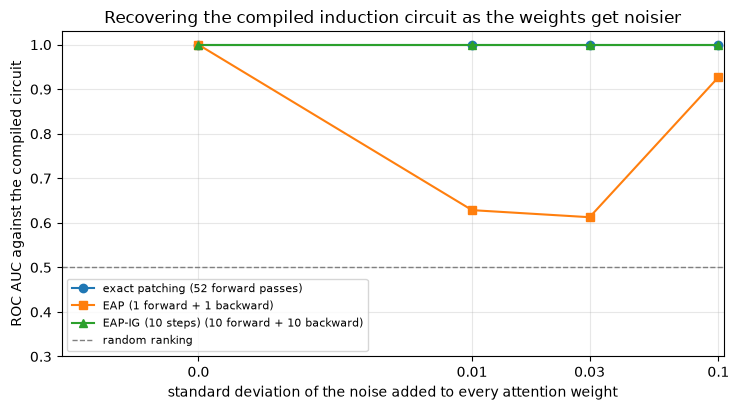

In [ ]:
SIGMAS = [0.0, 0.01, 0.03, 0.1]
noise_benches = {sigma: (clean_bench if sigma == 0.0 else benchmark(sigma, acdc_thresholds=(0.01,))) for sigma in SIGMAS}
aucs = {name: [noise_benches[s]["auc"][name] for s in SIGMAS] for name in clean_bench["scores"]}
costs = {"exact patching": "52 forward passes", "EAP": "1 forward + 1 backward", "EAP-IG (10 steps)": "10 forward + 10 backward"}
utils.plot_auc_vs_noise(SIGMAS, aucs, "Recovering the compiled induction circuit as the weights get noisier", costs)

print(f"{'sigma':>6} " + " ".join(f"{name:>18}" for name in aucs) + "   ACDC (tau=0.01): ground truth / others")
for i, sigma in enumerate(SIGMAS):
    circuit = noise_benches[sigma]["acdc"][0.01]
    tr = noise_benches[sigma]["truth"]
    print(f"{sigma:>6} " + " ".join(f"{aucs[name][i]:>18.3f}" for name in aucs) + f"   {int((circuit & tr).sum())}/7 / {int((circuit & ~tr).sum())}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace"> sigma     exact patching                EAP  EAP-IG (10 steps)   ACDC (tau=0.01): ground truth / others
   0.0              1.000              1.000              1.000   7/7 / 0
  0.01              1.000              0.629              1.000   7/7 / 0
  0.03              1.000              0.613              1.000   7/7 / 0
   0.1              1.000              0.927              1.000   7/7 / 32</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

Read the low-noise points first. At $\sigma=0.01$ and $0.03$, EAP falls to AUC 0.629 and 0.613, despite the model retaining 100% task accuracy. Exact patching and ten-step
edge-mask IG stay at 1.000; ACDC keeps all seven planted edges and no others. The dashed 0.5 line is the expected AUC of a random ranking, not a separately fitted method.

The final point is a useful surprise: EAP recovers to 0.927 at $\sigma=0.1$. More noise does not monotonically hurt a gradient method. The less confident, partly broken model has
different local derivatives. Meanwhile ACDC keeps 32 additional edges. Those are outside the *planted* circuit, but noise has introduced new dependencies, so calling all 32 false
discoveries would overstate what our answer key establishes.

The legend gives the main scoring cost, excluding shared caches and the reference forward pass for exact patching. AUC is a ranking measure; it does not compare circuit size,
whole-circuit faithfulness, or elapsed time. We turn to the mechanism of EAP's failure next.
</details>

## Summary of 2️⃣

- On the clean model, exact patching, EAP and edge-mask IG all rank the seven planted edges perfectly. Tiny EAP scores win because the distractors have exactly zero effect.
- Small weight perturbations break that convenience without breaking task accuracy: EAP drops toward the random-ranking baseline, while the other rankings remain perfect in this run.
- ACDC recovers seven edges at low noise, but keeps many more once the model's behavior degrades. Its threshold, KL objective and returned set answer a different question from a ranking AUC.
- We have isolated a failure worth explaining: the model still solves induction, but the local gradient no longer reliably identifies the program that solves it.

# 3️⃣ Why Gradients Fail, and What Fixes Them

> ##### Learning Objectives
>
> - Distinguish saturation of the output (the metric) from saturation of attention
> - See the QK fix recover a saturated head's queries and keys exactly, and fail for nodes whose effect passes *through* a saturated head
> - Understand why integrated gradients handle both

## Two kinds of saturation

There are two places in this model where a gradient can vanish:

- **The output.** The compiled model predicts the right token with probability $\approx 1$. The gradient of $\log p$ with respect to the correct logit is $1 - p \approx 0$, so *every* gradient of the log-probability metric is tiny, whatever happens inside the model.
- **Attention.** The program-relevant selected rows attend with nearly hard 0/1 patterns. The gradient of a saturated softmax with respect to its scores is $\approx 0$, so changes to a head's queries or keys look harmless to first order, however much they would really move the pattern. This is exactly the saturation that [8.3]'s QK fix was designed for.

Let's separate them, at the level of nodes, with [8.3]'s own implementations. We'll compute exact patching effects, AtP and AtP with the QK fix for the query, key, value and output
of every head, using two metrics: the log probability of the correct token (saturated at the output), and the correct token's logit minus the mean logit (not saturated at the
output, because logits are linear in the residual stream).


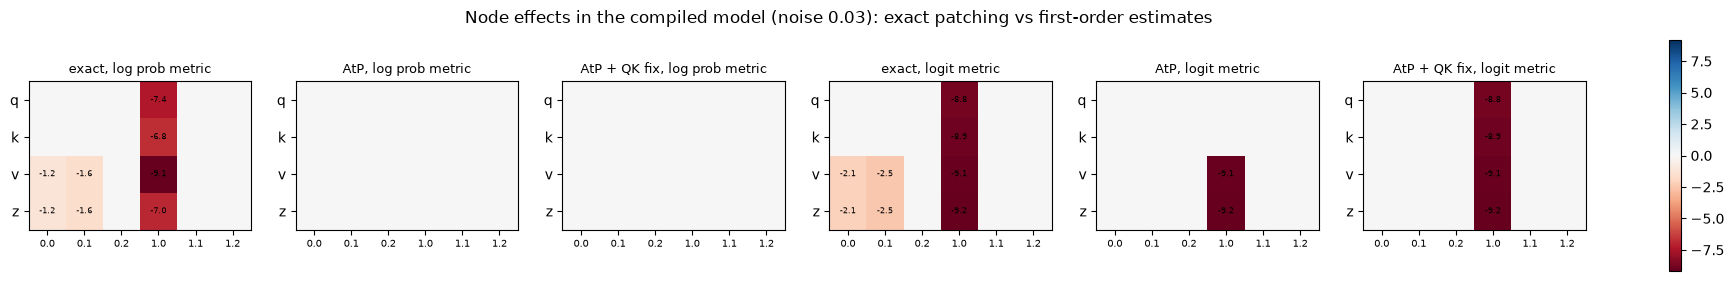

In [ ]:
node_model = add_weight_noise(compile_induction(), 0.03)
node_model.set_use_split_qkv_input(False)
targets = clean[:, POS.start + 1 : POS.stop + 1, None]


def logprob_metric(logits: Tensor, answers: Tensor) -> Tensor:
    return logits[:, POS].log_softmax(-1).gather(-1, targets)[..., 0].mean(-1)


def logit_metric(logits: Tensor, answers: Tensor) -> Tensor:
    logits = logits[:, POS]
    return (logits.gather(-1, targets)[..., 0] - logits.mean(-1)).mean(-1)


clean_nodes, corrupt_nodes = atp_8_3.cache_nodes(node_model, clean), atp_8_3.cache_nodes(node_model, corrupt)
node_results = {}
for metric_name, metric_fn in [("log prob", logprob_metric), ("logit", logit_metric)]:
    task = eap_8_2.Task(clean, corrupt, clean, metric_fn)
    grads = atp_8_3.node_gradients(node_model, task)
    node_results[metric_name] = {
        "exact": atp_8_3.exact_node_effects(node_model, task, clean_nodes, corrupt_nodes).cpu(),
        "AtP": atp_8_3.atp_estimates(clean_nodes, corrupt_nodes, grads).mean(-1).cpu(),
        "AtP + QK fix": atp_8_3.atp_qk_fixed(clean_nodes, corrupt_nodes, grads).mean(-1).cpu(),
    }

utils.plot_node_scores(
    {f"{method}, {metric_name} metric": node_results[metric_name][method] for metric_name in ["log prob", "logit"] for method in ["exact", "AtP", "AtP + QK fix"]},
    atp_8_3.KINDS,
    "Node effects in the compiled model (noise 0.03): exact patching vs first-order estimates",
)

Let's print the nodes that matter, so we can read the numbers off:

In [ ]:
rows = []
for kind, layer, head in [("v", 0, 0), ("v", 0, 1), ("q", 1, 0), ("k", 1, 0), ("v", 1, 0), ("z", 1, 0)]:
    k = atp_8_3.KINDS.index(kind)
    row = {"node": f"{kind}{layer}.{head}"}
    for metric_name in ["log prob", "logit"]:
        for method in ["exact", "AtP", "AtP + QK fix"]:
            row[f"{metric_name}: {method}"] = round(node_results[metric_name][method][k, layer, head].item(), 3)
    rows.append(row)
display(pd.DataFrame(rows).set_index("node"))

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">      log prob: exact  log prob: AtP  log prob: AtP + QK fix  logit: exact  \
node                                                                         
v0.0           -1.211          0.002                   0.002        -2.124   
v0.1           -1.600          0.002                   0.002        -2.489   
q1.0           -7.374          0.000                  -0.020        -8.817   
k1.0           -6.765          0.000                  -0.020        -8.920   
v1.0           -9.147         -0.021                  -0.021        -9.096   
z1.0           -6.953         -0.021                  -0.021        -9.177   

      logit: AtP  logit: AtP + QK fix  
node                                   
v0.0       0.027                0.027  
v0.1      -0.004               -0.004  
q1.0       0.000               -8.817  
k1.0       0.000               -8.920  
v1.0      -9.096               -9.096  
z1.0      -9.177               -9.177  </pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

Start with the **log-probability** columns. Exact corruption of `q1.0` changes the metric by -7.374, but AtP rounds to zero and the QK fix gives only -0.020. Repairing the head's
attention calculation cannot repair a vanishing gradient of the *output metric*.

Now read the **logit** columns. AtP correctly recovers the direct value and output effects (`v1.0` and `z1.0`), because the remaining path to this metric is linear. It still misses
the saturated query and key effects. Combining the logit metric with the QK fix recovers `q1.0` and `k1.0` exactly to the printed precision: -8.817 and -8.920.

Finally inspect `v0.0` and `v0.1`. Their exact logit effects are -2.124 and -2.489, but even the QK-fixed estimates stay near zero. These are **values of earlier heads** whose
effects pass through the induction head's saturated attention. The QK fix changes how we score a patched head's own queries and keys; it does not replace every downstream saturated
computation.

The signs here use [8.3]'s convention, **corrupted minus clean**, so a useful node generally has a negative score. The earlier edge table used clean minus corrupted. Compare effect
magnitudes and causal pathways across the two tables, rather than treating the opposite signs as a contradiction.
</details>

### Exercise - does the metric rescue EAP?

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Rerun the edge benchmark from 2️⃣ with the logit metric (`benchmark(sigma, metric_kind="logit")`) for each noise level, and compare the AUCs with the log-probability ones. Store
the complete benchmark result for each noise level in `logit_benches` (a dict mapping each sigma in `SIGMAS` to the dict returned by `benchmark`). Then extract `logit_aucs`, in the
same format as `aucs`: method name → list of AUCs in `SIGMAS` order. The display code uses `logit_benches[0.03]["scores"]["EAP"]` to inspect individual edge scores as well as the
aggregate AUCs. Before running it: which method should improve, and which ground-truth edges will EAP still miss?

In [ ]:
logit_benches = {}  # sigma -> full benchmark result, including scores and AUCs
logit_aucs = {}  # method name -> list of AUCs, one per sigma
print(f"{'sigma':>6} " + " ".join(f"{name + ' (logit)':>26}" for name in logit_aucs))
for i, sigma in enumerate(SIGMAS):
    print(f"{sigma:>6} " + " ".join(f"{logit_aucs[name][i]:>26.3f}" for name in logit_aucs))
eap_gt = logit_benches[0.03]["scores"]["EAP"]
print("\nEAP (logit metric, sigma = 0.03) on the ground-truth edges:",
      {f"{s}->{r}": round(eap_gt[graph.index(s, r)].item(), 3) for s, r in GROUND_TRUTH_EDGES})

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace"> sigma     exact patching (logit)                EAP (logit)  EAP-IG (10 steps) (logit)
   0.0                      1.000                      1.000                      1.000
  0.01                      1.000                      0.568                      1.000
  0.03                      1.000                      0.575                      1.000
   0.1                      1.000                      0.971                      1.000

EAP (logit metric, sigma = 0.03) on the ground-truth edges: {'input-&gt;0.0&lt;v&gt;': -0.027, 'input-&gt;0.1&lt;v&gt;': 0.004, '0.0-&gt;1.0&lt;k&gt;': -0.0, '0.1-&gt;1.0&lt;k&gt;': -0.0, 'input-&gt;1.0&lt;q&gt;': -0.0, 'input-&gt;1.0&lt;v&gt;': 9.108, '1.0-&gt;logits': 9.177}</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

Changing the output metric does **not** rescue the ranking at small noise: EAP's logit AUC is 0.568 at 0.01 and 0.575 at 0.03, slightly below the corresponding log-probability results. That is not evidence against the saturation explanation. The printed edge scores show exactly what changed: `input->1.0<v>` and `1.0->logits` now have substantial scores, 9.108 and 9.177, while the query/key paths remain near zero.

Removing output saturation rescues effects with a linear downstream path. It leaves attention saturation in place, including for upstream values that change the induction head's keys. AUC combines all seven edges into one number, so improving two effects need not improve the overall ranking. Exact patching and edge-mask IG still rank all seven above the other edges here. Their agreement in this small experiment is evidence about these settings, not a guarantee for every metric or interpolation path.
</details>


<details><summary>Solution</summary>

```python
logit_benches = {sigma: benchmark(sigma, metric_kind="logit") for sigma in SIGMAS}
logit_aucs = {name: [logit_benches[s]["auc"][name] for s in SIGMAS] for name in clean_bench["scores"]}
print(f"{'sigma':>6} " + " ".join(f"{name + ' (logit)':>26}" for name in logit_aucs))
for i, sigma in enumerate(SIGMAS):
    print(f"{sigma:>6} " + " ".join(f"{logit_aucs[name][i]:>26.3f}" for name in logit_aucs))
eap_gt = logit_benches[0.03]["scores"]["EAP"]
print("\nEAP (logit metric, sigma = 0.03) on the ground-truth edges:",
      {f"{s}->{r}": round(eap_gt[graph.index(s, r)].item(), 3) for s, r in GROUND_TRUTH_EDGES})
```
</details>

## Summary of 3️⃣

- Output saturation and attention saturation are separate obstacles. A logit metric removes the first; the QK fix repairs the second for a head's own query/key intervention.
- In the node table, combining them recovers the induction head's query/key effects, while upstream value effects remain badly underestimated because they pass through another saturated computation.
- The edge ranking need not improve when some effect estimates improve: at low noise, logit-metric EAP still misses most of the planted paths.
- Integrated gradients samples away from the clean endpoint and recovers the planted ranking in this experiment. Its finite-step accuracy and path choice remain things to check, rather than assume.

# 4️⃣ No Answer Key: GPT-2, and Choosing a Method

> ##### Learning Objectives
>
> - Measure agreement between methods when there's no ground truth, and understand why agreement isn't correctness
> - Compare circuits from different methods at matched size on held-out prompts
> - Choose a circuit-discovery method for a given model, budget and question

## What we can measure without ground truth

On a real model there is no program to compare against. What's left is:

- **agreement** between methods: if EAP, EAP-IG and ACDC pick largely the same edges, that's some evidence (though methods can share blind spots, as EAP and AtP shared one above);
- **faithfulness** on held-out prompts at matched size, against random circuits, as in [8.4];
- **cost**.

We'll measure all three on GPT-2 Small's greater-than task, with the GPT-2 graph and functions from [8.2] and [8.4]. ACDC is the expensive one: it takes a few minutes on a GPU.

In [ ]:
gpt2 = HookedTransformer.from_pretrained("gpt2-small", device=device)
gpt2.requires_grad_(False)
gpt2.set_use_split_qkv_input(True)  # as in [8.2] and [8.4]: hooks on each head's q/k/v input
gpt2.set_use_hook_mlp_in(True)
gt = eap_8_2.make_greater_than_task(gpt2, 64, seed=0)
gt_heldout = eap_8_2.make_greater_than_task(gpt2, 64, seed=1)
EDGES = eap_8_2.EDGE_MASK
print(f"{int(EDGES.sum()):,} edges; clean metric {eap_8_2.mean_metric(gpt2, gt, gt.clean_tokens):.3f}, corrupt metric {eap_8_2.mean_metric(gpt2, gt, gt.corrupt_tokens):.3f}")

gpt2_timings, gpt2_scores = {}, {}
t0 = time.time()
gpt2_scores["EAP"] = eap_8_2.eap_scores(gpt2, gt).cpu()
gpt2_timings["EAP"] = time.time() - t0
t0 = time.time()
gpt2_scores["EAP-IG"] = eap_8_2.eap_ig_scores(gpt2, gt, n_steps=5).cpu()
gpt2_timings["EAP-IG"] = time.time() - t0

gt_corrupt_out = eap_8_2.sender_activations(gpt2, gt.corrupt_tokens)
with t.no_grad():
    gt_full_logprobs = gpt2(gt.clean_tokens)[:, -1:].log_softmax(-1)


@t.inference_mode()
def gpt2_kl(circuit: Tensor) -> float:
    logits = acdc_utils.gpt2_circuit_logits(gpt2, gt.clean_tokens, gt_corrupt_out, circuit, EDGES, eap_8_2)
    return acdc_8_4.kl_divergence(logits[:, None], gt_full_logprobs).item()


t0 = time.time()
acdc_circuit, acdc_tested = acdc_8_4.acdc(gpt2_kl, EDGES, acdc_8_4.gpt2_receiver_order(), acdc_8_4.gpt2_receiver_owner(), threshold=0.01)
gpt2_timings["ACDC"] = time.time() - t0
for name, seconds in gpt2_timings.items():
    print(f"{name:<7} {seconds:6.1f}s")
print(f"ACDC kept {int(acdc_circuit.sum())} edges after testing {acdc_tested:,}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">32,491 edges; clean metric 0.847, corrupt metric -0.585
EAP        0.3s
EAP-IG     0.7s
ACDC     380.4s
ACDC kept 65 edges after testing 3,203</pre>

</details>

### Exercise - agreement and faithfulness at matched size

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15 minutes on this exercise.
> ```

<details>
<summary>Hint - separate selection from evaluation</summary>

Construct all three circuits using the seed-0 discovery results, then keep them fixed while evaluating `gt_heldout`. For Jaccard, count only the union and intersection of the
boolean masks; do not include the thousands of shared absent edges. For faithfulness, normalise the circuit metric by the same full and empty baselines for every method. Compare
with random circuits at exactly the same $k$.
</details>

Let $k$ be the number of edges in ACDC's circuit. Build the top-$k$ circuits for EAP and EAP-IG (by absolute score, with `eap_8_2.top_k_circuit`), and:

1. compute the **Jaccard index** $|A \cap B| / |A \cup B|$ for every pair of the three circuits, and also for two random circuits of size $k$ (the agreement you'd expect by chance);
2. compute each circuit's **faithfulness** on the held-out prompts (use `eap_8_2.run_with_circuit`, which returns the mean task metric with every edge outside the circuit corrupted, and normalise between the full model and the empty circuit), plus the faithfulness of 10 random circuits of size $k$.

Store the results in `agreement` (a dict from a pair name to a Jaccard index) and `faithful` (a dict from a method name to its faithfulness).

In [ ]:
agreement, faithful = {}, {}

print(f"circuit size k = {k}")
for name, value in agreement.items():
    print(f"  Jaccard {name:<18} {value:.2f}")
for name, value in faithful.items():
    print(f"  faithfulness {name:<22} {value:.2f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">circuit size k = 65
  Jaccard ACDC vs EAP        0.40
  Jaccard ACDC vs EAP-IG     0.53
  Jaccard EAP vs EAP-IG      0.57
  Jaccard random vs random   0.00
  faithfulness ACDC                   0.78
  faithfulness EAP                    0.49
  faithfulness EAP-IG                 0.72
  faithfulness random (median of 10)  -0.00</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

All three circuits contain 65 edges, so size alone cannot explain their differences. Their Jaccard indices, 0.40-0.57, exceed the displayed random-pair overlap of 0.00, yet they
are far from identical. EAP and EAP-IG agree most, but the highest agreement does not identify the most faithful pair.

On the separately sampled seed-1 batch, ACDC retains 0.78 of the clean-versus-corrupt task-metric gap, EAP-IG retains 0.72, and EAP retains 0.49. The median of ten same-size random
circuits is approximately zero. These circuits therefore preserve substantially more task behavior than arbitrary edge sets; none preserves the full gap.

Faithfulness is $[m(C)-m(\varnothing)]/[m(\mathrm{full})-m(\varnothing)]$, not accuracy and not a fraction of correctly identified edges. Values can fall outside [0, 1]. The code
uses the fully corrupted run as the empty-circuit baseline. ACDC was selected using KL divergence to the full output distribution, whereas the reported faithfulness uses the
greater-than task metric; that is a deliberate comparison across objectives.

Here “held-out” means a second sample generated with a different seed and unused for circuit selection. The generator does not enforce disjoint prompt identities across the two
batches, and no overlap audit is saved, so this is not evidence for an independently deduplicated test set. Nor does it establish a true GPT-2 circuit. It is a controlled
behavioral comparison at one size, threshold and task.
</details>


<details><summary>Solution</summary>

```python
def jaccard(a: Tensor, b: Tensor) -> float:
    return ((a & b).sum() / (a | b).sum()).item()


k = int(acdc_circuit.sum())
circuits = {
    "ACDC": acdc_circuit.cpu(),
    "EAP": eap_8_2.top_k_circuit(gpt2_scores["EAP"], k).cpu(),
    "EAP-IG": eap_8_2.top_k_circuit(gpt2_scores["EAP-IG"], k).cpu(),
}
generator = t.Generator().manual_seed(0)
random_circuits = [acdc_8_4.random_circuit(EDGES, k, generator) for _ in range(10)]
agreement = {f"{a} vs {b}": jaccard(circuits[a], circuits[b]) for a, b in [("ACDC", "EAP"), ("ACDC", "EAP-IG"), ("EAP", "EAP-IG")]}
agreement["random vs random"] = jaccard(random_circuits[0], random_circuits[1])

full = eap_8_2.mean_metric(gpt2, gt_heldout, gt_heldout.clean_tokens)
empty = eap_8_2.mean_metric(gpt2, gt_heldout, gt_heldout.corrupt_tokens)
faithful = {name: (eap_8_2.run_with_circuit(gpt2, gt_heldout, c) - empty) / (full - empty) for name, c in circuits.items()}
faithful["random (median of 10)"] = float(np.median([(eap_8_2.run_with_circuit(gpt2, gt_heldout, c) - empty) / (full - empty) for c in random_circuits]))

print(f"circuit size k = {k}")
for name, value in agreement.items():
    print(f"  Jaccard {name:<18} {value:.2f}")
for name, value in faithful.items():
    print(f"  faithfulness {name:<22} {value:.2f}")
```
</details>

## Choosing a method

The experiments suggest a workflow rather than a universal winner:

| Your immediate question | Useful starting point | Check before trusting it |
| --- | --- | --- |
| Which edges are worth investigating on a large graph? | EAP for a cheap first ranking | Audit important edges with finite interventions; inspect metric and attention saturation. |
| Does saturation make that ranking unstable? | EAP-IG or a targeted AtP QK fix | Compare interpolation step counts; distinguish direct query/key effects from upstream effects. |
| What happens if this specific edge is corrupted? | Exact patching | Specify the corruption, metric and surrounding circuit; redundancy makes isolated-edge effects context dependent. |
| Can I remove edges while preserving the model's output distribution? | ACDC with an explicit KL threshold | Inspect cost, pruning order, threshold sensitivity and behavior on evaluation prompts. |
| Does the candidate explanation preserve the task behavior? | Matched-size faithfulness against random circuits | Evaluate separately sampled prompts and controls, and check overlap before claiming an independent test. |
| Does a proposed causal story survive stronger tests? | Causal scrubbing from [8.5] | Choose resampling rules that test the actual hypothesis; a successful discovery ranking is only a starting point. |

For this GPT-2 run, EAP took 0.3 s, five-step EAP-IG 0.7 s, and ACDC 380.4 s. These are measurements from the saved run, not hardware-independent speed ratios. ACDC achieved the
largest reported faithfulness; EAP-IG was close at much lower measured cost. That makes a gradient ranking followed by targeted exact checks a useful first pass for this setting.
It does not eliminate the need to validate the resulting circuit.

Keep the two IG implementations distinct: the compiled-model exercise interpolates **edge masks**, while the imported GPT-2 implementation from [8.2] interpolates **input
embeddings**. The saturation lesson motivates both, but their scores and completeness paths are not interchangeable.

## Try it yourself - break a method

The compiled model is a laboratory: you can build in any property you want to test. Some ideas:

- **Make the backup really redundant.** Give head 0.1 a much larger `amplitude` than 0.0, so that 0.0 adds almost nothing on top of it. Which methods still find `0.0 -> 1.0<k>`? Does ACDC's answer depend on which of the two it tests first?
- **Soften the attention.** Recompile with `sharpness=2`. The model gets worse, but are the gradient methods happier?
- **Add a distractor that matters a little.** Make head 1.2 write a small multiple of the current token into `out` instead of `junk`. Is it in the circuit? What would you want a method to say about it?

Use `benchmark` (you can pass it a modified `compile_induction` by redefining the function) and `roc_auc`.

In [ ]:
def compile_soft_induction(sharpness: float = 2.0) -> HookedTransformer:
    """The induction program with soft attention everywhere."""
    model = make_empty_model()
    tok, pos, prev, out, junk = (SUBSPACES[k] for k in ["tok", "pos", "prev", "out", "junk"])
    with t.no_grad():
        model.embed.W_E[:, tok] = t.eye(VOCAB, device=device)
        model.pos_embed.W_pos[:, pos] = t.eye(SEQ, device=device)
        model.unembed.W_U[out, :] = 10 * t.eye(VOCAB, device=device)
    previous_position = t.diag(t.ones(SEQ - 1), diagonal=-1)
    for head in [0, 1]:
        compile_select_aggregate(model, 0, head, pos, pos, previous_position, tok, prev, sharpness=sharpness)
    compile_select_aggregate(model, 0, 2, pos, pos, t.zeros(SEQ, SEQ), tok, junk)
    compile_select_aggregate(model, 1, 0, tok, prev, t.eye(VOCAB), tok, out, sharpness=sharpness)
    compile_select_aggregate(model, 1, 1, junk, junk, t.eye(VOCAB), junk, junk)
    compile_select_aggregate(model, 1, 2, pos, pos, t.eye(SEQ), tok, junk)
    return model


original_compile = compile_induction
compile_induction = compile_soft_induction
try:
    soft = benchmark(0.03)
finally:
    compile_induction = original_compile
with t.no_grad():
    print(f"soft attention: log prob of the answer {induction_logprob(add_weight_noise(compile_soft_induction(), 0.03)(clean)):.3f}")
for name, auc in soft["auc"].items():
    print(f"  {name:<18} AUC {auc:.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">soft attention: log prob of the answer -0.482
  exact patching     AUC 1.000
  EAP                AUC 1.000
  EAP-IG (10 steps)  AUC 1.000</pre>

</details>

With soft attention and the same noise level 0.03, EAP returns to AUC 1.000, matching exact patching and edge-mask IG. Compare this with 0.613 for the sharp model. Softening
attention makes local derivatives informative again in this run. It also changes the model: the mean answer log probability is -0.482 rather than -0.0026. The demonstration
therefore trades confident execution of the program for a smoother function; it is not a free repair of the original model.

Try changing only `sharpness` first, keeping the data and weight-noise seed fixed. Record both task behavior and circuit recovery. If you change the backup or add an output-writing
distractor, revisit `GROUND_TRUTH_EDGES` before treating the old AUC as an answer key: you have changed the program whose circuit is being judged.

## Summary of 4️⃣

- Without a known program, compare agreement, behavioral faithfulness and cost separately. Agreement above random is useful evidence, but shared blind spots remain possible.
- On GPT-2 Small's greater-than task, the saved 65-edge circuits retain 0.49-0.78 of the evaluation batch's task-metric gap, against approximately zero for random circuits of the same size.
- The compiled-model play cell turns the saturation explanation into a prediction: soften attention, and EAP's ranking improves. It does, while the model's confidence falls.
- The practical endpoint is a candidate circuit plus an account of what was tested: graph, corruption, objective, size, sample construction and controls. Further causal testing is part of interpreting that candidate.

## Limitations

The compiled benchmark has two layers, six attention heads, no MLPs or layernorm, fixed orthogonal variable blocks, one program and one weight-noise seed. It lets us isolate a
failure mechanism; it does not estimate how often that mechanism dominates in trained models. Its seven planted edges are conditional on the clean/corrupt contrast, and cease to be
a complete causal answer key after noise adds other dependencies.

The GPT-2 comparison uses one task, 64 discovery prompts, 64 separately sampled evaluation prompts, one ACDC threshold and one circuit size. No prompt-overlap audit or sampling
uncertainty is shown, and the ten random circuits provide a control rather than a confidence interval. Use the figures to explain these observed failures and tradeoffs; broader
method rankings require additional programs, seeds and independently checked evaluation sets.

# ☆ Bonus

## Real Tracr

Tracr itself ([github.com/google-deepmind/tracr](https://github.com/google-deepmind/tracr)) compiles full RASP programs, including `map` (into MLPs) and numerical variables, and the ACDC paper benchmarks on two of its programs (`reverse` and `x-proportion`). It's built on JAX and Haiku; if you can install it, compile `make_frac_prevs` and port its weights into a TransformerLens model, and rerun the benchmark. How do the methods do on a circuit that includes MLPs?

## Compile a `map`

Extend the compiler with `compile_map(model, layer, in_space, out_space, table)`, which writes an MLP implementing a lookup table from one categorical variable to another (one
hidden neuron per input value, with a ReLU). Use it to compile "predict the successor of the token after the previous occurrence", and add MLP senders and receivers to the graph.

## InterpBench

Compiled models are unnaturally clean even with noise: their circuits are sparse, their subspaces orthogonal. **InterpBench** (Gupta et al., 2024) instead *trains* models to
implement known circuits, using strict interchange intervention training, so that the result has realistic representations but still a known ground truth. Read the paper, and
compare its findings about which methods work with yours.

## Further reading

- Weiss, Goldberg & Yahav (2021), [*Thinking Like Transformers*](https://arxiv.org/abs/2106.06981). RASP.
- Lindner, Kramár, Farquhar, Rahtz, McGrath & Mikulik (2023), [*Tracr: Compiled Transformers as a Laboratory for Interpretability*](https://arxiv.org/abs/2301.05062).
- Conmy et al. (2023), [*Towards Automated Circuit Discovery for Mechanistic Interpretability*](https://arxiv.org/abs/2304.14997). Section 4 benchmarks ACDC, SP and HISP on Tracr models and hand-found circuits.
- Gupta, Arcuschin, Kwa & Garriga-Alonso (2024), [*InterpBench: Semi-Synthetic Transformers for Evaluating Mechanistic Interpretability Techniques*](https://arxiv.org/abs/2407.14494).
- Hanna, Pezzelle & Belinkov (2024), [*Have Faith in Faithfulness*](https://arxiv.org/abs/2403.17806). EAP-IG, and why overlap with a reference circuit isn't the same as faithfulness.
- Kramár, Lieberum, Shah & Nanda (2024), [*AtP\**](https://arxiv.org/abs/2403.00745), for the saturation failure modes you met in 3️⃣.